In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import PowerTransformer
import matplotlib.pyplot as plt
import seaborn as sns

#Load data

In [ ]:
df = pd.read_csv("app_user_behavior_dataset.csv")
pd.set_option('display.max_columns', None)
df.head()

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,5,8,8,1,0,20,Basic,9,5,2,NaN,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,7,3,7,0,0,7,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,5,2,21,1,0,33,Free,11,6,1,2.0,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,8,4,13,0,0,17,Basic,6,3,1,3.0,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,7,3,15,0,0,21,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign


Understand the data

In [ ]:
df.shape

(50000, 25)

In [ ]:
df.isnull().sum()/len(df)*100

,0
user_id,0.000
age,0.000
gender,0.000
country,0.000
device_type,0.000
app_version,0.000
sessions_per_week,0.000
avg_session_duration_min,0.000
daily_active_minutes,0.000
feature_clicks_per_session,0.000


In [ ]:
df["rating_given"].value_counts()

,count
rating_given,
4.0,17465
3.0,11199
5.0,9911
2.0,3885
1.0,2518


In [ ]:
df.describe()

,user_id,age,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,44978.000000,50000.000000,50000.000000,50000.000000
mean,124999.500000,38.513040,1.476126,7.999680,13.149842,45.164537,12.013920,4.99662,3.999060,13.470760,0.397520,0.19666,22.038240,5.995800,3.002260,2.001440,3.630664,0.500834,64.940409,603.785100
std,14433.901067,12.094948,0.470158,2.829438,8.946944,19.505118,3.480289,2.23518,1.997763,6.343635,0.633992,0.44442,12.985237,2.453313,1.731818,1.413435,1.087339,0.288578,14.838827,345.567524
min,100000.000000,18.000000,1.000000,0.000000,0.060000,5.000000,1.000000,0.00000,0.000000,3.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,10.000000,7.000000
25%,112499.750000,28.000000,1.100000,6.000000,6.570000,31.650000,10.000000,3.00000,3.000000,8.000000,0.000000,0.00000,11.000000,4.000000,2.000000,1.000000,3.000000,0.250000,54.900000,302.000000
50%,124999.500000,39.000000,1.200000,8.000000,11.240000,45.210000,12.000000,5.00000,4.000000,13.000000,0.000000,0.00000,22.000000,6.000000,3.000000,2.000000,4.000000,0.500000,65.025000,604.000000
75%,137499.250000,49.000000,2.000000,10.000000,17.570000,58.440000,14.000000,6.00000,5.000000,19.000000,1.000000,0.00000,33.000000,8.000000,4.000000,3.000000,4.000000,0.750000,75.090000,906.000000
max,149999.000000,59.000000,2.100000,26.000000,91.400000,129.130000,28.000000,16.00000,19.000000,24.000000,5.000000,4.00000,44.000000,19.000000,13.000000,11.000000,5.000000,1.000000,100.000000,1199.000000


#impute null values

In [ ]:
df["rating_given"] = df["rating_given"].fillna(df["rating_given"].median())
df["rating_given"].isnull().sum()

np.int64(0)

Find Duplicate values

In [ ]:
df.duplicated().sum()

np.int64(0)

#Detecting incorrect values

In [ ]:

cat_col = df.select_dtypes(include = ["object"]).columns
cat_col

Index(['gender', 'country', 'device_type', 'subscription_type',
       'marketing_source'],
      dtype='object')

In [ ]:
for i in cat_col:
  print(df[i].value_counts())
  print("*"*50)

gender
Female    23994
Male      23936
Other      2070
Name: count, dtype: int64
**************************************************
country
India        22550
USA           9115
UK            5043
Canada        3853
Australia     3498
Germany       3425
Singapore     2516
Name: count, dtype: int64
**************************************************
device_type
Android    27315
iOS        17662
Web         5023
Name: count, dtype: int64
**************************************************
subscription_type
Free       30088
Basic      12495
Premium     7417
Name: count, dtype: int64
**************************************************
marketing_source
Organic           17539
Google Ads        12468
Referral           7539
Facebook Ads       7463
Email Campaign     4991
Name: count, dtype: int64
**************************************************


#handling outlier

In [ ]:
num_col = df.select_dtypes(include = "number").columns

In [ ]:
for i in num_col:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3-Q1
  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  outliers = df[(df[i] < lower) | (df[i] > upper)]
  print(i, ":", len(outliers), "outliers")



user_id : 0 outliers
age : 0 outliers
app_version : 0 outliers
sessions_per_week : 181 outliers
avg_session_duration_min : 1572 outliers
daily_active_minutes : 181 outliers
feature_clicks_per_session : 745 outliers
notifications_opened_per_week : 660 outliers
in_app_search_count : 1054 outliers
pages_viewed_per_session : 0 outliers
crash_events_last_30_days : 398 outliers
support_tickets_raised : 8910 outliers
days_since_last_login : 0 outliers
ads_clicked_last_30_days : 70 outliers
content_downloads : 622 outliers
social_shares : 219 outliers
rating_given : 2518 outliers
churn_risk_score : 0 outliers
engagement_score : 167 outliers
account_age_days : 0 outliers


In [ ]:
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df.loc[
        (df[col] < lower) | (df[col] > upper), col
    ]

    if len(outliers) > 0:
        print(f"\n{col}:")
        print("Lower limit:", lower)
        print("Upper limit:", upper)
        print("Outlier values:", outliers.tolist()[:10])


sessions_per_week:
Lower limit: 0.0
Upper limit: 16.0
Outlier values: [18, 18, 18, 17, 17, 26, 19, 17, 21, 17]

avg_session_duration_min:
Lower limit: -9.93
Upper limit: 34.07
Outlier values: [34.27, 38.01, 34.64, 59.19, 35.16, 39.86, 35.61, 44.46, 34.22, 39.0]

daily_active_minutes:
Lower limit: -8.535000000000004
Upper limit: 98.625
Outlier values: [105.87, 106.11, 117.64, 99.65, 103.68, 99.03, 102.78, 104.6, 103.95, 98.91]

feature_clicks_per_session:
Lower limit: 4.0
Upper limit: 20.0
Outlier values: [22, 24, 21, 24, 21, 21, 21, 23, 21, 21]

notifications_opened_per_week:
Lower limit: -1.5
Upper limit: 10.5
Outlier values: [11, 11, 11, 11, 12, 11, 11, 12, 11, 13]

in_app_search_count:
Lower limit: 0.0
Upper limit: 8.0
Outlier values: [9, 10, 11, 9, 9, 9, 9, 9, 9, 10]

crash_events_last_30_days:
Lower limit: -1.5
Upper limit: 2.5
Outlier values: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

support_tickets_raised:
Lower limit: 0.0
Upper limit: 0.0
Outlier values: [2, 1, 1, 1, 1, 1, 1, 1, 1, 1]



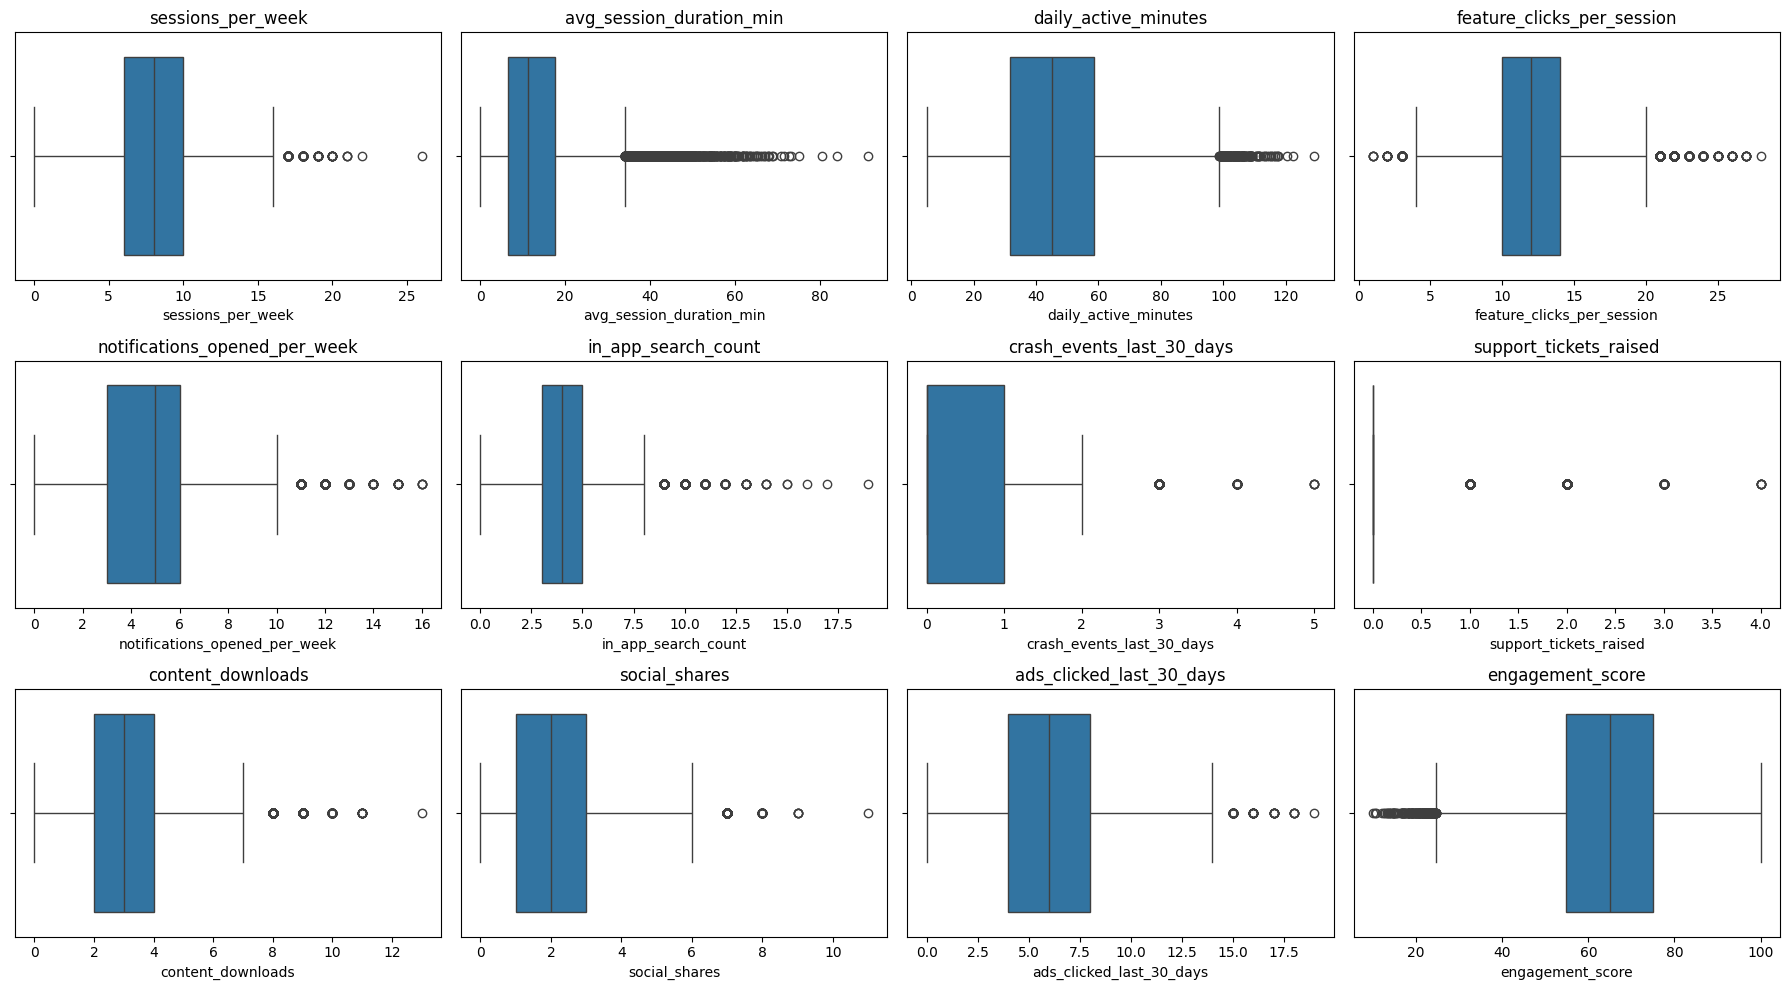

In [ ]:
cap_cols = ['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
            'feature_clicks_per_session', 'notifications_opened_per_week',
            'in_app_search_count', 'crash_events_last_30_days',
            'support_tickets_raised', 'content_downloads', 'social_shares',
            'ads_clicked_last_30_days', 'engagement_score']
plt.figure(figsize=(18, 10))

for i, col in enumerate(cap_cols):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [ ]:
for col in cap_cols:
    low, high = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(low, high)


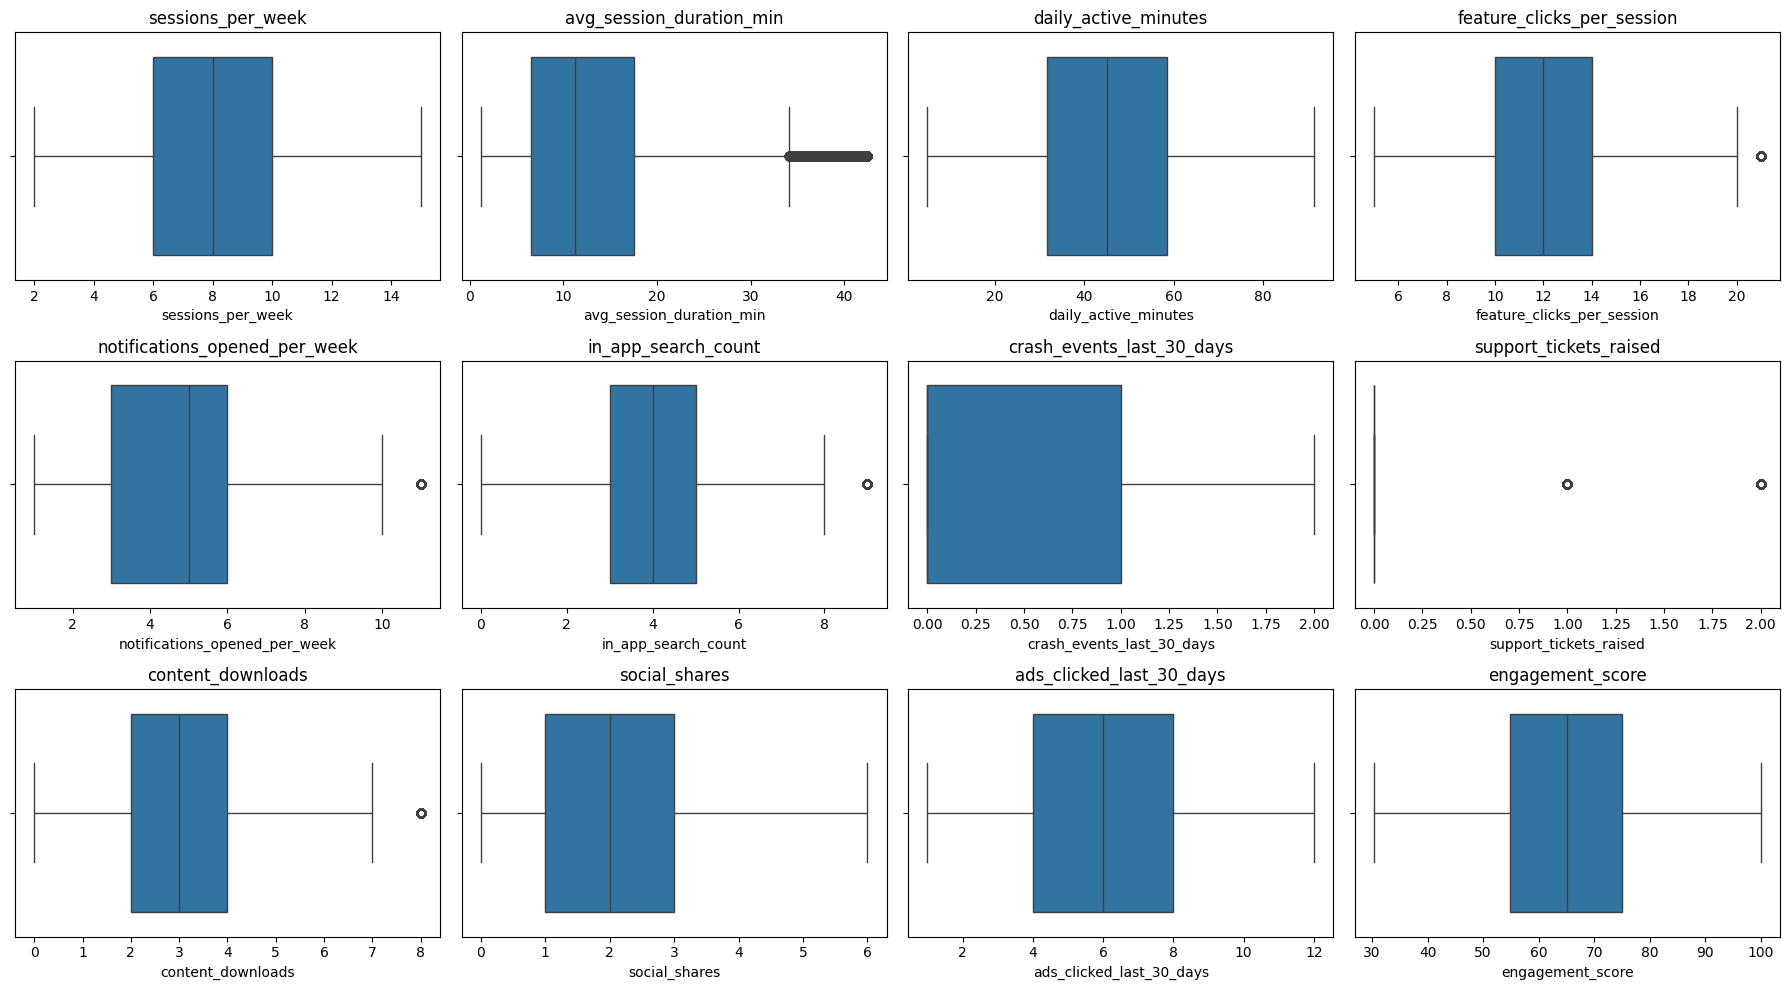

In [ ]:
plt.figure(figsize=(18, 10))
for i, col in enumerate(cap_cols):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


#Handel skewness

In [ ]:
df_original = df.copy()

In [ ]:

for i in num_cols:
    print(i, ":", df[i].skew())

user_id : 0.0
age : 0.0022370864932634445
app_version : 0.38262482593715663
sessions_per_week : 0.275279659664212
avg_session_duration_min : 1.1149065038262618
daily_active_minutes : 0.037734880713292035
feature_clicks_per_session : 0.25708551315789346
notifications_opened_per_week : 0.39386261433317143
in_app_search_count : 0.36669291710899654
pages_viewed_per_session : 0.005384270096965685
crash_events_last_30_days : 1.2932288687745015
support_tickets_raised : 2.132907764042606
days_since_last_login : -0.005849394940339704
ads_clicked_last_30_days : 0.30878845645433706
content_downloads : 0.5032080237552721
social_shares : 0.5981555429920814
rating_given : -0.8048143806240994
churn_risk_score : -0.004396679461402927
engagement_score : -0.0008423626695217511
account_age_days : -0.0046074992355710845


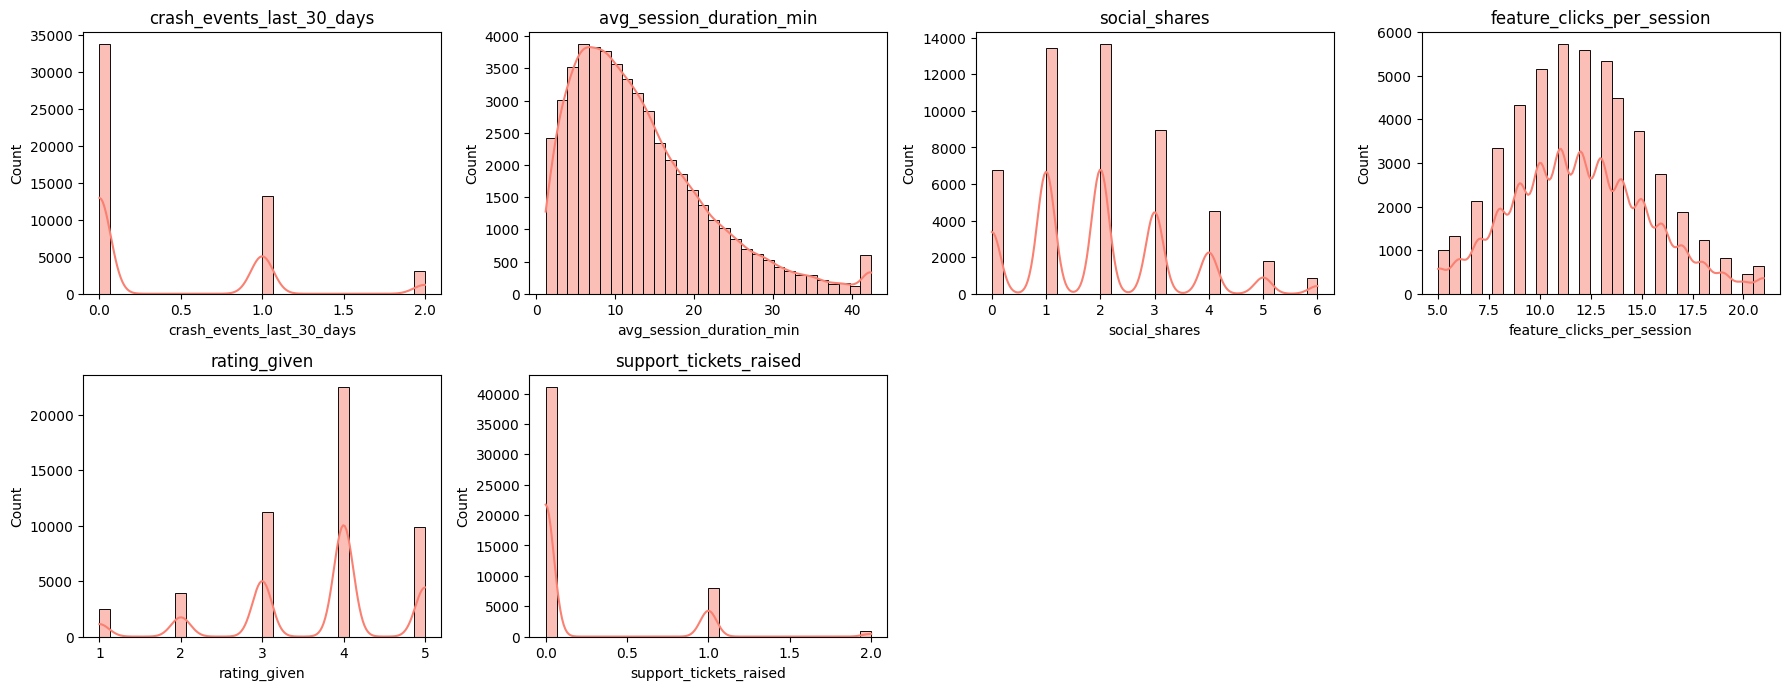

In [ ]:
cols = [
    "crash_events_last_30_days",
    "avg_session_duration_min",
    "social_shares",
    "feature_clicks_per_session",
    "rating_given",
    "support_tickets_raised"
]
plt.figure(figsize=(18, 10))

for i, col in enumerate(cols):
    plt.subplot(3, 4, i + 1)
    sns.histplot(df[col], bins=30, kde=True, color='salmon')
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
pt = PowerTransformer(method="yeo-johnson")
df[cols] = pt.fit_transform(df[cols])

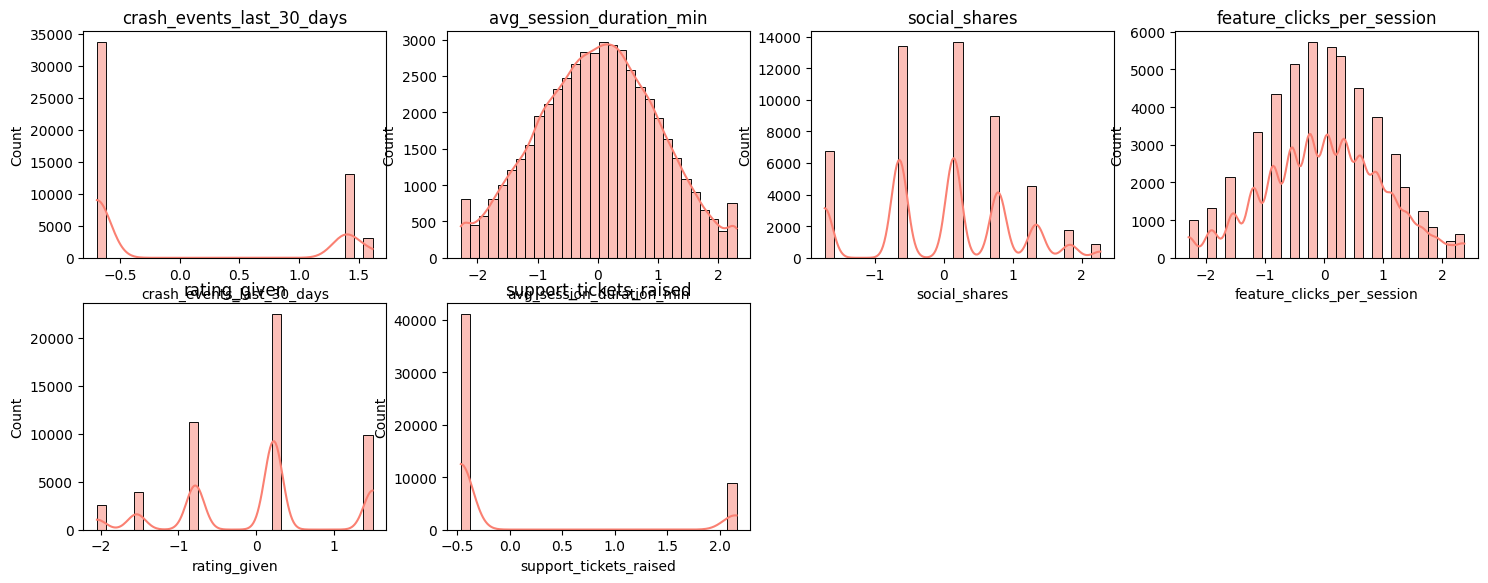

In [ ]:
plt.figure(figsize=(18, 10))

for i, col in enumerate(cols):
    plt.subplot(3, 4, i + 1)
    sns.histplot(df[col], bins=30, kde=True, color='salmon')
    plt.title(col)

In [ ]:
for i in num_cols:
    print(i, ":", df[i].skew())

user_id : 0.0
age : 0.0022370864932634445
app_version : 0.38262482593715663
sessions_per_week : 0.275279659664212
avg_session_duration_min : -0.020665707127930866
daily_active_minutes : 0.037734880713292035
feature_clicks_per_session : -0.01878456533389827
notifications_opened_per_week : 0.39386261433317143
in_app_search_count : 0.36669291710899654
pages_viewed_per_session : 0.005384270096965685
crash_events_last_30_days : 0.7506923058224824
support_tickets_raised : 1.6818813678701048
days_since_last_login : -0.005849394940339704
ads_clicked_last_30_days : 0.30878845645433706
content_downloads : 0.5032080237552721
social_shares : -0.041838688997071646
rating_given : -0.1516776175403792
churn_risk_score : -0.004396679461402927
engagement_score : -0.0008423626695217511
account_age_days : -0.0046074992355710845


#Final check

In [ ]:
df.shape

(50000, 25)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_id                        50000 non-null  int64  
 1   age                            50000 non-null  int64  
 2   gender                         50000 non-null  object 
 3   country                        50000 non-null  object 
 4   device_type                    50000 non-null  object 
 5   app_version                    50000 non-null  float64
 6   sessions_per_week              50000 non-null  int64  
 7   avg_session_duration_min       50000 non-null  float64
 8   daily_active_minutes           50000 non-null  float64
 9   feature_clicks_per_session     50000 non-null  float64
 10  notifications_opened_per_week  50000 non-null  int64  
 11  in_app_search_count            50000 non-null  int64  
 12  pages_viewed_per_session       50000 non-null 

In [ ]:
df.describe()

,user_id,age,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days
count,50000.000000,50000.000000,50000.000000,50000.000000,5.000000e+04,50000.000000,5.000000e+04,50000.000000,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.000000,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.000000,50000.000000,50000.000000
mean,124999.500000,38.513040,1.476126,7.987420,-1.128342e-16,45.096211,-9.053025e-16,4.994740,3.985620,13.470760,9.620749e-17,-1.841727e-16,22.038240,5.984080,2.996680,2.387424e-17,-1.585931e-16,0.500834,64.990445,603.785100
std,14433.901067,12.094948,0.470158,2.776072,1.000010e+00,19.321008,1.000010e+00,2.193565,1.956029,6.343635,1.000010e+00,1.000010e+00,12.985237,2.403602,1.712883,1.000010e+00,1.000010e+00,0.288578,14.706899,345.567524
min,100000.000000,18.000000,1.000000,2.000000,-2.274073e+00,5.000000,-2.296481e+00,1.000000,0.000000,3.000000,-6.946291e-01,-4.656612e-01,0.000000,1.000000,0.000000,-1.722460e+00,-2.048225e+00,0.000000,30.369900,7.000000
25%,112499.750000,28.000000,1.100000,6.000000,-7.047047e-01,31.650000,-5.491819e-01,3.000000,3.000000,8.000000,-6.946291e-01,-4.656612e-01,11.000000,4.000000,2.000000,-6.419726e-01,-7.836233e-01,0.250000,54.900000,302.000000
50%,124999.500000,39.000000,1.200000,8.000000,1.695402e-02,45.210000,5.215167e-02,5.000000,4.000000,13.000000,-6.946291e-01,-4.656612e-01,22.000000,6.000000,3.000000,1.451237e-01,2.250762e-01,0.500000,65.025000,604.000000
75%,137499.250000,49.000000,2.000000,10.000000,7.034062e-01,58.440000,6.163045e-01,6.000000,5.000000,19.000000,1.393192e+00,-4.656612e-01,33.000000,8.000000,4.000000,7.869958e-01,2.250762e-01,0.750000,75.090000,906.000000
max,149999.000000,59.000000,2.100000,15.000000,2.301450e+00,91.360100,2.381548e+00,11.000000,9.000000,24.000000,1.615803e+00,2.160338e+00,44.000000,12.000000,8.000000,2.270554e+00,1.497858e+00,1.000000,100.000000,1199.000000


In [ ]:
df.head(3)

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,-1.435414,52.71,0.338391,5,8,8,1.393192,-0.465661,20,Basic,9,5,0.145124,0.225076,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,1.262197,42.03,-1.544276,7,3,7,-0.694629,-0.465661,7,Free,8,3,0.786996,-0.783623,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,-0.953502,76.69,-1.544276,5,2,21,1.393192,-0.465661,33,Free,11,6,-0.641973,-1.537537,0.63,42.49,678,Google Ads


#Save data

In [ ]:
df.to_csv("app_user_behavior_preprocess.csv",index=False)